# Feature Engineering
### Data Science Core Concepts 101 — by Yunhan Jin

Feature engineering transforms raw data into inputs that models can learn from effectively. It's one of the highest-leverage steps in the DS workflow — better features often matter more than better models.

This notebook builds on the housing dataset from the EDA section.

---

## Setup
Recreating the cleaned housing dataset from the EDA notebook.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
%matplotlib inline

np.random.seed(42)
n = 200

neighborhoods = ['Downtown', 'Midtown', 'Uptown', 'Suburbs']
base_prices   = {'Downtown': 800000, 'Midtown': 600000, 'Uptown': 500000, 'Suburbs': 350000}
conditions    = ['Poor', 'Fair', 'Good', 'Excellent']

records = []
for i in range(n):
    nbhd  = np.random.choice(neighborhoods)
    sqft  = max(600, int(np.random.normal(1500, 400)))
    price = int(base_prices[nbhd] + sqft * 150 + np.random.normal(0, 50000))
    year  = np.random.randint(2019, 2024)
    month = np.random.randint(1, 13)
    day   = np.random.randint(1, 28)
    records.append({
        'price':        price,
        'sqft':         sqft,
        'bedrooms':     np.random.choice([1, 2, 3, 4, 5], p=[0.1, 0.25, 0.35, 0.2, 0.1]),
        'bathrooms':    np.random.choice([1.0, 1.5, 2.0, 2.5, 3.0]),
        'neighborhood': nbhd,
        'condition':    np.random.choice(conditions, p=[0.05, 0.20, 0.50, 0.25]),
        'year_built':   int(np.random.normal(1990, 20)),
        'has_garage':   np.random.choice([True, False], p=[0.6, 0.4]),
        'sold':         np.random.choice([0, 1], p=[0.3, 0.7]),
        'listing_date': f"{year}-{month:02d}-{day:02d}"
    })

df = pd.DataFrame(records)

# Apply EDA cleaning
df['bathrooms']    = df['bathrooms'].fillna(df['bathrooms'].median())
df['year_built']   = df['year_built'].astype('Int64')
df['sold']         = df['sold'].astype(bool)
df['listing_date'] = pd.to_datetime(df['listing_date'])
df['condition']    = pd.Categorical(df['condition'],
                                    categories=['Poor', 'Fair', 'Good', 'Excellent'],
                                    ordered=True)

print(f"Dataset shape: {df.shape}")
df.head()

Dataset shape: (200, 10)


,price,sqft,bedrooms,bathrooms,neighborhood,condition,year_built,has_garage,sold,listing_date
0,717621,1279,3,2.0,Uptown,Good,1972,False,False,2023-05-07
1,526776,1335,2,3.0,Suburbs,Good,2000,True,True,2022-05-01
2,801656,1399,5,1.0,Midtown,Poor,1966,True,True,2021-12-23
3,496164,1650,3,2.5,Suburbs,Fair,2012,True,False,2020-05-02
4,732847,1022,2,2.5,Midtown,Fair,2004,True,False,2022-02-06


---
## Section 1: Encoding Categorical Variables
Models require numeric input. Categorical columns must be converted to numbers — but the method depends on the variable type.

### 1.1 Label Encoding — Ordinal
For ordinal variables, map each category to an integer that preserves the order.

In [2]:
# Map ordinal categories to integers that preserve ranking
condition_map = {'Poor': 0, 'Fair': 1, 'Good': 2, 'Excellent': 3}
df['condition_encoded'] = df['condition'].map(condition_map)

df[['condition', 'condition_encoded']].value_counts().sort_index()

condition  condition_encoded
Poor       0                     8
           1                     0
           2                     0
           3                     0
Fair       0                     0
           1                    44
           2                     0
           3                     0
Good       0                     0
           1                     0
           2                    91
           3                     0
Excellent  0                     0
           1                     0
           2                     0
           3                    57
Name: count, dtype: int64

### 1.2 One-Hot Encoding — Nominal
For nominal variables, create a binary column for each category. No ordering is implied.

Use `drop_first=True` to avoid multicollinearity — if you have 4 neighborhoods, 3 columns are enough to represent all combinations.

In [3]:
df = pd.get_dummies(df, columns=['neighborhood'], drop_first=True)

# Each new column = 1 if the row belongs to that neighborhood, 0 otherwise
ohe_cols = [c for c in df.columns if c.startswith('neighborhood_')]
df[ohe_cols].head()

,neighborhood_Midtown,neighborhood_Suburbs,neighborhood_Uptown
0,False,False,True
1,False,True,False
2,True,False,False
3,False,True,False
4,True,False,False


### 1.3 Binary Encoding
Boolean columns (`True`/`False`) need to be cast to `int` (1/0) for models. This is the reverse of what we did in EDA — database stores 0/1 → EDA casts to bool for readability → feature engineering casts back to int for modeling.

In [4]:
df['has_garage'] = df['has_garage'].astype(int)
df['sold']       = df['sold'].astype(int)

df[['has_garage', 'sold']].head()

,has_garage,sold
0,0,0
1,1,1
2,1,1
3,1,0
4,1,0


---
## Section 2: Scaling Numeric Features
Many models are sensitive to the scale of input features — a column with values in the millions will dominate one with values 0–5. Scaling puts them on equal footing.

**When to scale:** linear models, neural networks, KNN, SVM.

**When NOT to scale:** tree-based models (XGBoost, Random Forest, LightGBM) — they split on thresholds and are scale-invariant.

### 2.1 Standardization (Z-score)
Transforms to mean=0, std=1. The most common choice — use when you don't know the data's range, or when outliers are present.

In [5]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
df['sqft_scaled'] = scaler.fit_transform(df[['sqft']])

print(f"Original sqft   — mean: {df['sqft'].mean():.1f}, std: {df['sqft'].std():.1f}")
print(f"Scaled sqft     — mean: {df['sqft_scaled'].mean():.4f}, std: {df['sqft_scaled'].std():.4f}")

Original sqft   — mean: 1584.2, std: 427.3
Scaled sqft     — mean: 0.0000, std: 1.0025


### 2.2 Min-Max Normalization
Scales to a fixed range [0, 1]. Use when you need bounded values — e.g. for neural network inputs.

In [6]:
from sklearn.preprocessing import MinMaxScaler

mm_scaler = MinMaxScaler()
df['sqft_normalized'] = mm_scaler.fit_transform(df[['sqft']])

print(f"Normalized sqft — min: {df['sqft_normalized'].min():.4f}, max: {df['sqft_normalized'].max():.4f}")

Normalized sqft — min: 0.0000, max: 1.0000


---
## Section 3: Creating New Features
New features derived from existing columns can capture signals that raw values miss. This is where domain knowledge pays off.

### 3.1 From Existing Numeric Columns

In [7]:
# Price per square foot — normalizes price by size
df['price_per_sqft'] = df['price'] / df['sqft']

# House age — more interpretable than raw year
df['house_age'] = 2024 - df['year_built'].astype(float)

# Room ratio — density of bathrooms relative to bedrooms
df['bath_per_bed'] = df['bathrooms'] / df['bedrooms']

df[['price_per_sqft', 'house_age', 'bath_per_bed']].describe()

,price_per_sqft,house_age,bath_per_bed
count,200.000000,200.000000,200.000000
mean,538.695955,34.280000,0.805542
std,203.663827,19.254487,0.502423
min,277.302866,-13.000000,0.200000
25%,388.159333,22.000000,0.500000
50%,487.913951,33.000000,0.666667
75%,626.757164,46.000000,1.000000
max,1647.020000,88.000000,3.000000


### 3.2 From Datetime Columns
Extract components that capture seasonality and time-based patterns.

In [8]:
df['listing_year']    = df['listing_date'].dt.year
df['listing_month']   = df['listing_date'].dt.month
df['listing_quarter'] = df['listing_date'].dt.quarter
df['is_summer']       = df['listing_month'].isin([6, 7, 8]).astype(int)  # binary flag

df[['listing_date', 'listing_year', 'listing_month', 'listing_quarter', 'is_summer']].head()

,listing_date,listing_year,listing_month,listing_quarter,is_summer
0,2023-05-07,2023,5,2,0
1,2022-05-01,2022,5,2,0
2,2021-12-23,2021,12,4,0
3,2020-05-02,2020,5,2,0
4,2022-02-06,2022,2,1,0


### 3.3 Interaction Features
Multiply or combine two features to capture joint effects that neither captures alone.

In [9]:
# Total rooms — combined bedroom + bathroom count
df['total_rooms'] = df['bedrooms'] + df['bathrooms']

# Size with garage — captures whether a large home also has parking
df['sqft_x_garage'] = df['sqft'] * df['has_garage']

df[['total_rooms', 'sqft_x_garage']].head()

,total_rooms,sqft_x_garage
0,5.0,0
1,5.0,1335
2,6.0,1399
3,5.5,1650
4,4.5,1022


---
## Section 4: Handling Skewed Features
Many DS datasets have right-skewed numeric columns — a few extreme values drag the mean up. Log transformation compresses the scale and makes distributions more symmetric, which improves performance for linear models.

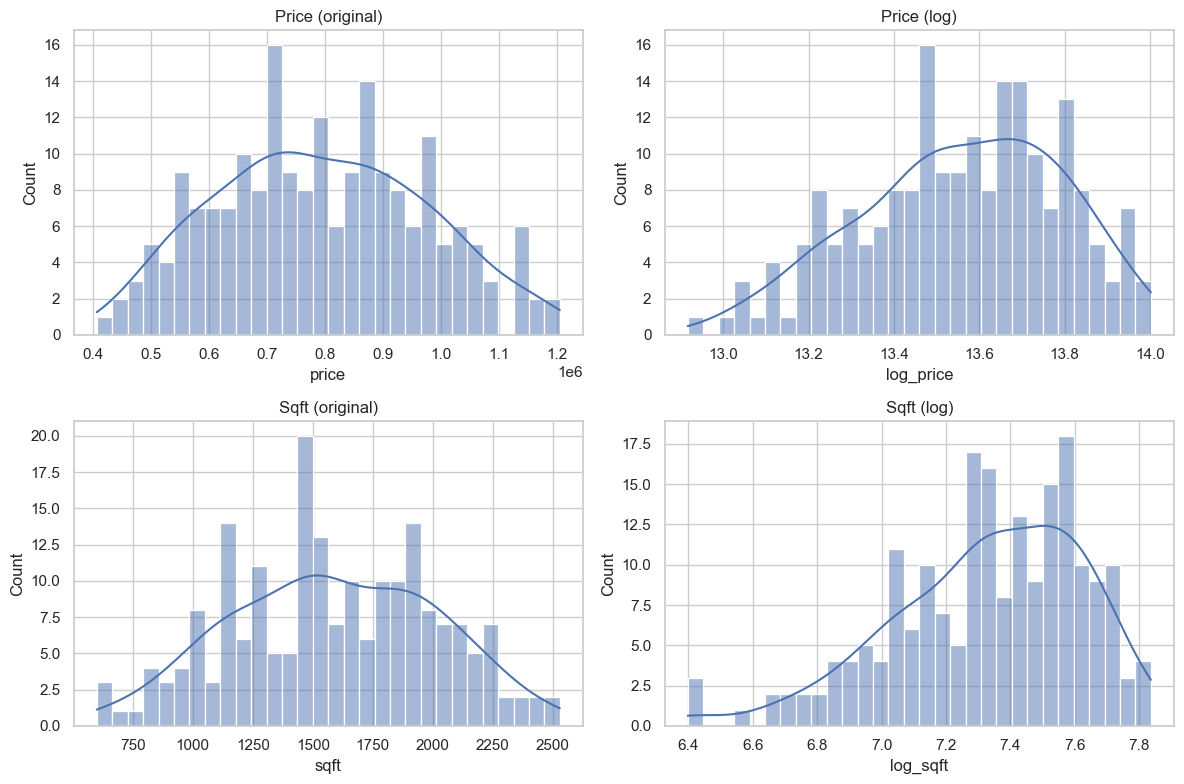

In [10]:
df['log_price'] = np.log1p(df['price'])  # log1p = log(1 + x), handles zero safely
df['log_sqft']  = np.log1p(df['sqft'])

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

sns.histplot(df['price'],     bins=30, kde=True, ax=axes[0, 0]).set_title('Price (original)')
sns.histplot(df['log_price'], bins=30, kde=True, ax=axes[0, 1]).set_title('Price (log)')
sns.histplot(df['sqft'],      bins=30, kde=True, ax=axes[1, 0]).set_title('Sqft (original)')
sns.histplot(df['log_sqft'],  bins=30, kde=True, ax=axes[1, 1]).set_title('Sqft (log)')

plt.tight_layout()
plt.show()

---
## Section 5: Feature Selection
More features isn't always better. Irrelevant or redundant features add noise and slow down training.

### 5.1 Correlation-Based
If two features are highly correlated, they carry redundant information. Drop one.

In [11]:
numeric_df = df.select_dtypes(include='number')
corr = numeric_df.corr().abs()

# Find pairs with correlation > 0.85 (excluding self-correlation)
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
high_corr = [(col, row, upper.loc[row, col])
             for col in upper.columns
             for row in upper.index
             if upper.loc[row, col] > 0.85]

print("Highly correlated pairs (> 0.85):")
for a, b, v in sorted(high_corr, key=lambda x: -x[2]):
    print(f"  {a} & {b}: {v:.2f}")

Highly correlated pairs (> 0.85):
  sqft_scaled & sqft: 1.00
  sqft_normalized & sqft_scaled: 1.00
  sqft_normalized & sqft: 1.00
  house_age & year_built: 1.00
  log_price & price: 0.99
  log_sqft & sqft: 0.98
  log_sqft & sqft_scaled: 0.98
  log_sqft & sqft_normalized: 0.98
  listing_quarter & listing_month: 0.97
  sqft_x_garage & has_garage: 0.93


### 5.2 Low Variance
A feature that barely changes across rows adds no signal — every row looks the same to the model.

In [12]:
from sklearn.feature_selection import VarianceThreshold

numeric_df = df.select_dtypes(include='number').dropna(axis=1)
selector   = VarianceThreshold(threshold=0.01)
selector.fit(numeric_df)

low_var = numeric_df.columns[~selector.get_support()].tolist()
print(f"Low variance features: {low_var if low_var else 'None'}")

Low variance features: None


### 5.3 Domain Knowledge
Not everything needs to be automated. Sometimes you know a feature is meaningless for the prediction task — drop it.

Examples for housing price prediction:
- `listing_date` itself — raw date is not predictive, but extracted components (month, quarter) are
- `id` — arbitrary identifier with no signal
- Redundant engineered features — if you created `log_price` as a target transformation, don't also keep raw `price` as a feature

---
## Final Feature Set
After engineering and selection, assemble the final feature matrix ready for modeling.

In [13]:
feature_cols = [
    'sqft', 'bedrooms', 'bathrooms',
    'condition_encoded', 'has_garage', 'sold',
    'price_per_sqft', 'house_age', 'bath_per_bed', 'total_rooms',
    'listing_month', 'listing_quarter', 'is_summer',
    'log_sqft'
] + [c for c in df.columns if c.startswith('neighborhood_')]

X = df[feature_cols]
y = df['log_price']  # log-transformed target

print(f"Feature matrix shape: {X.shape}")
print(f"Target shape: {y.shape}")
X.head()

Feature matrix shape: (200, 17)
Target shape: (200,)


,sqft,bedrooms,bathrooms,condition_encoded,has_garage,sold,price_per_sqft,house_age,bath_per_bed,total_rooms,listing_month,listing_quarter,is_summer,log_sqft,neighborhood_Midtown,neighborhood_Suburbs,neighborhood_Uptown
0,1279,3,2.0,2,0,0,561.079750,52.0,0.666667,5.0,5,2,0,7.154615,False,False,True
1,1335,2,3.0,2,1,1,394.588764,24.0,1.500000,5.0,5,2,0,7.197435,False,True,False
2,1399,5,1.0,0,1,1,573.020729,58.0,0.200000,6.0,12,4,0,7.244228,True,False,False
3,1650,3,2.5,1,1,0,300.705455,12.0,0.833333,5.5,5,2,0,7.409136,False,True,False
4,1022,2,2.5,1,1,0,717.071429,20.0,1.250000,4.5,2,1,0,6.930495,True,False,False
